<a href="https://colab.research.google.com/github/deivsonpires/analise-de-dados-em-python/blob/main/An%C3%A1lise%20Final/An%C3%A1lise_de_dados_em_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Começar devagar ou acelarado? Uma análise exploratória de desempenho (Resultados Maratona de boston 2015-2017)

**Dataset utilizado**: https://www.kaggle.com/datasets/rojour/boston-results

**Pergunta central**: Qual a estratégia dá o melhor resultado: começar devagar ou acelerado?

**Hipotéses**:

1.   *Otimização de tempo:* Corredores que iniciam a prova de forma mais conservadora obtêm tempo final médio significativamente menor;
2.   *A parede dos 30km:* Corredores que iniciam a prova de forma forte perdem velocidade nos km finais;
1.   *Fator preparação:* Corredores mais rápidos tendem a realizar uma prova em ritmo mais uniforme.

**Como executar**: Fazer upload dos arquivos .csv do dataset dentro da IDE do collab e posteriormente clicar em "Executar tudo".


#1. Preparando dados para testar as hipotéses

**Bibliotecas utilizadas**:
*   Pandas;
*   Numpy;
*   Matpotlib.

Nesta etapa, a função `preparar_dados()` centraliza todo o pré-processamento da base da Maratona de Boston (2015, 2016 e 2017) e cria as métricas necessárias para testar as três hipóteses do projeto.

##Limpeza e tratamento de dados
* *Unificação de dados(`pd.concat`):* Os três arquivos CSV (2015, 2016 e 2017) são consolidados em um único *DataFrame* com **79.638 registros** iniciais;
* *Remoção de duplicados (`drop_duplicates`):* Verifica e elimina linhas idênticas da base (nenhuma linha duplicada foi encontrada);
* *Padronização de tipos (`pd.to_timedelta`):* As colunas de tempo (5K, 10K, 15K, 20K, Half, 25K, 30K, 35K, 40K e Official Time) vêm originalmente como texto no formato HH:MM:SS. Todas são convertidas para valores numéricos em **minutos** para permitir cálculos estatísticos e aritméticos;
* *Valores ausentes (`errors='coerce'` e `dropna`):* Corredores que não foram registrados em alguma parcial de tempo aparecem com o caractere '-' no dataset original. O parâmetro `errors='coerce'` transforma essas falhas em valores nulos (`NaN`), e o método `dropna(subset=colunas_tempo)` remove esses registros incompletos.

Como a análise depende da comparação exata entre trechos de 5 km, preencher parciais faltantes com médias artificiais distorceria o cálculo de ritmo. A limpeza de dados remove apenas **600 linhas** (0,75% da base), preservando **79.038 corredores válidos** (99,25% dos dados).



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def preparar_dados():
    arquivos = [
        'marathon_results_2015.csv',
        'marathon_results_2016.csv',
        'marathon_results_2017.csv'
    ]
    df = pd.concat([pd.read_csv(arq) for arq in arquivos], ignore_index=True)
    df = df.drop_duplicates()

    colunas_tempo = ['5K', '10K', '15K', '20K', 'Half', '25K', '30K', '35K', '40K', 'Official Time']
    for col in colunas_tempo:
        df[col] = pd.to_timedelta(df[col], errors='coerce').dt.total_seconds() / 60

    df = df.dropna(subset=colunas_tempo).copy()

    df['Segunda_Metade'] = df['Official Time'] - df['Half']
    df['Estrategia'] = np.where(df['Segunda_Metade'] < df['Half'], 'Começou Devagar', 'Começou Acelerado')

    marcos = ['5K', '10K', '15K', '20K', '25K', '30K', '35K', '40K']
    df['Ritmo_5K'] = df['5K'] / 5
    for i in range(1, len(marcos)):
        df[f'Ritmo_{marcos[i]}'] = (df[marcos[i]] - df[marcos[i - 1]]) / 5

    colunas_ritmo = [f'Ritmo_{m}' for m in marcos]
    df['Desvio_Ritmo'] = df[colunas_ritmo].std(axis=1)
    df['Variacao_Ritmo'] = pd.qcut(
        df['Desvio_Ritmo'],
        q=3,
        labels=['Baixa Variação', 'Média Variação', 'Alta Variação']
    )
    return df, colunas_ritmo


df, colunas_ritmo = preparar_dados()
print('Registros válidos:', len(df))

Registros válidos: 79038


#2. Análise Parcial (Apresentação AV2)

Nesta etapa, a função `analise_parcial(df)` realiza um diagnóstico geral do comportamento dos **79.038 corredores válidos**, medindo o quanto o ritmo muda entre a primeira e a segunda metade da maratona.

##Construção de gráficos para análise

* *Classificação por faixas (`np.select`):* Segmenta os atletas em quatro perfis de ritmo: Negativo (< 0%, segunda metade mais rápida), Uniforme(0% a 5%), Positivo moderado (5% a 15%) e Positivo acentuado (> 15%);
* *Tratamento de escala no histograma (`clip(upper=60)`):* Agrupa na última barra do gráfico os valores extremos acima de 60% para evitar que poucos casos isolados distorçam a visualização do eixo horizontal;
* *Comparação lado a lado (`plt.subplots` e `normalize=True`):* Combina um histograma (frequência absoluta por faixa percentual, com linha de referência em 0%) e um gráfico de barras horizontais (proporção percentual de cada estratégia no total da base).

Assim como foi dito na apresentação anterior (Av2 - Apresentação parcial),mostra que a grande maioria dos corredores perde ritmo na segunda metade da maratona. Nos gráficos, **95,6%** dos atletas (**75.541 corredores**) completaram a segunda parte da prova mais devagar que a primeira, registrando uma queda mediana de **+10,6%** no ritmo. Somando os perfis de perda moderada (**43,7%**) e acentuada (**33,2%**), percebe-se que **76,9%** dos participantes desaceleraram mais de 5% após a metade do percurso.

Por outro lado, apenas **18,6%** mantiveram um ritmo **Uniforme** e somente **4,4%** (**3.497 corredores**) fizeram o *split* **Negativo** (correndo a segunda metade mais rápido que a primeira). Isso mostra que a maioria larga rápido demais e perde fôlego no final. A partir desse cenário, as próximas células investigam se essa minoria que começa mais devagar consegue tempos finais menores (**Hipótese 1**), em que momento da prova ocorre a quebra de rendimento (**Hipótese 2**) e como manter um ritmo constante melhora o resultado (**Hipótese 3**).


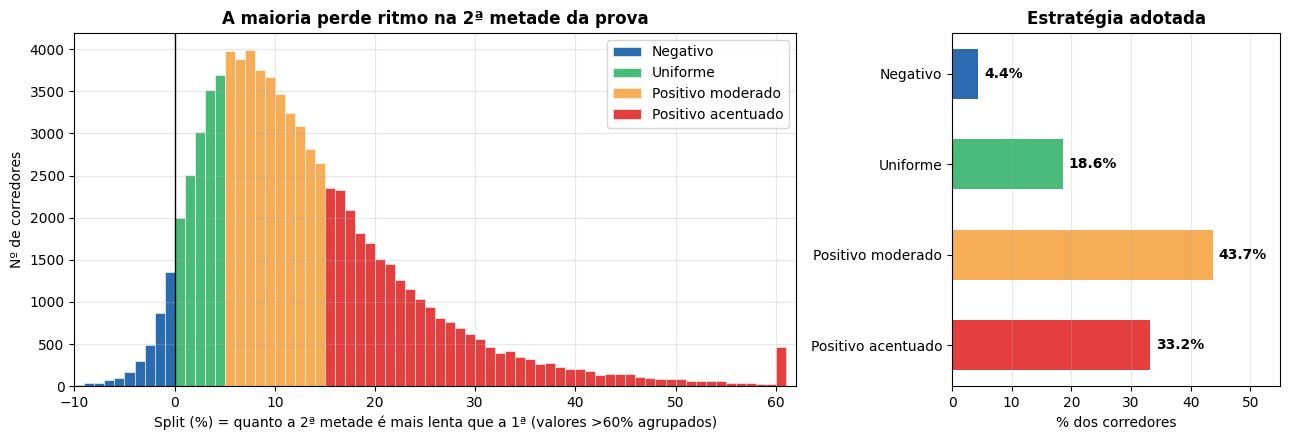

In [4]:
def analise_parcial(df):
    split_pct = ((df['Segunda_Metade'] - df['Half']) / df['Half']) * 100
    categorias = ['Negativo', 'Uniforme', 'Positivo moderado', 'Positivo acentuado']
    condicoes = [split_pct < 0, split_pct <= 5, split_pct <= 15]
    grupo = pd.Series(np.select(condicoes, categorias[:3], default=categorias[3]), index=df.index)

    cores = ['#2b6cb0', '#48bb78', '#f6ad55', '#e53e3e']
    bins = np.arange(-10, 62, 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})

    for cat, cor in zip(categorias, cores):
        ax1.hist(split_pct.clip(upper=60)[grupo == cat], bins=bins, color=cor, edgecolor='white', linewidth=0.4, label=cat)

    ax1.axvline(0, color='black', linewidth=1)
    ax1.set_title('A maioria perde ritmo na 2ª metade da prova', fontweight='bold')
    ax1.set_xlabel('Split (%) = quanto a 2ª metade é mais lenta que a 1ª (valores >60% agrupados)')
    ax1.set_ylabel('Nº de corredores')
    ax1.set_xlim(-10, 62)
    ax1.legend()
    ax1.grid(alpha=0.3)

    percentuais = (grupo.value_counts(normalize=True).reindex(categorias) * 100)[::-1]
    barras = ax2.barh(percentuais.index, percentuais.values, color=cores[::-1], height=0.55)
    ax2.bar_label(barras, fmt='%.1f%%', padding=4, fontweight='bold')
    ax2.set_title('Estratégia adotada', fontweight='bold')
    ax2.set_xlabel('% dos corredores')
    ax2.set_xlim(0, 55)
    ax2.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()


analise_parcial(df)

#3. Análise da Hipótese 1 (Otimização de tempo)

**Hipótese 1:** Corredores que iniciam a prova de forma mais conservadora obtêm tempo final médio significativamente menor.

Nesta etapa, a função `analise_hipotese_1(df)` testa a primeira hipótese do estudo, comparando o desempenho geral dos **79.038 corredores válidos** divididos por estratégia de ritmo.

### Construção de gráficos para análise
* *Agrupamento estatístico (`groupby` e `agg`)*: Agrupa os atletas pela coluna Estrategia (Começou Acelerado vs. Começou Devagar) e calcula simultaneamente a contagem, a média e a mediana do tempo oficial;
* *Gráfico de barras (`plt.bar` e `plt.bar_label`)*: Compara visualmente o tempo final médio de cada estratégia e exibe o valor exato em minutos no topo de cada barra para facilitar a leitura;

Ao observar a tabela gerada e o gráfico de barras, fica claro que a estratégia conservadora entrega resultados superiores. Os **3.497 corredores** (**4,4%**) que adotaram o perfil **Começou Devagar** (*negative split*, fazendo a segunda metade mais rápida que a primeira) concluíram a maratona com um tempo médio de **215,2 minutos** (cerca de 3h35min) e mediana de **210,6 minutos** (3h31min). Porém, os **75.541 corredores** (**95,6%**) que optaram pelo perfil **Começou Acelerado** registraram tempo médio de **233,9 minutos** (cerca de 3h54min) e mediana de **227,2 minutos** (3h47min).

Dessa forma é possível visualizar que quem controlou o ritmo no início completou a prova, em média, **18,7 minutos** (**8,0%**) mais rápido do que quem largou em ritmo agressivo. Esses números confirmam a Hipótese 1 e abrem caminho para a Hipótese 2, que investiga em que momento do percurso os corredores acelerados perdem rendimento.

                   count        mean      median
Estrategia                                      
Começou Acelerado  75541  233.854651  227.166667
Começou Devagar     3497  215.171185  210.550000


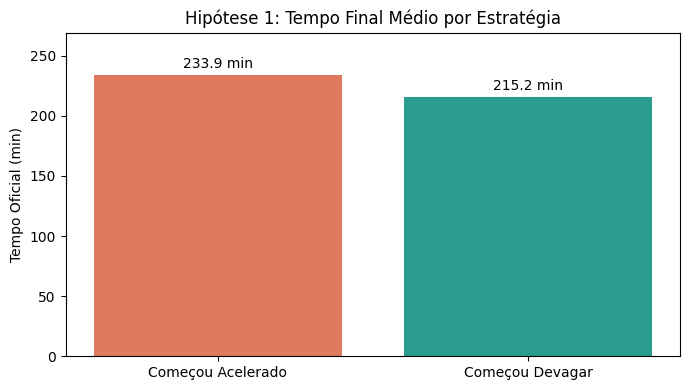

In [5]:
def analise_hipotese_1(df):
    resumo = df.groupby('Estrategia')['Official Time'].agg(['count', 'mean', 'median'])
    print(resumo)

    plt.figure(figsize=(7, 4))
    barras = plt.bar(resumo.index, resumo['mean'], color=['#e07a5f', '#2a9d8f'])
    plt.bar_label(barras, fmt='%.1f min', padding=3)
    plt.title('Hipótese 1: Tempo Final Médio por Estratégia')
    plt.ylabel('Tempo Oficial (min)')
    plt.ylim(0, resumo['mean'].max() * 1.15)
    plt.tight_layout()
    plt.show()


analise_hipotese_1(df)

#4. Análise da Hipótese 2 (A parede dos 30km)

**Hipótese 2:** Corredores que iniciam a prova de forma forte perdem velocidade nos km finais.

Nesta etapa, a função `analise_hipotese_2(df, colunas_ritmo)` testa a segunda hipótese do estudo, acompanhando a evolução do ritmo médio (*pace*, em minutos por quilômetro) a cada trecho de 5 km.

### Construção de gráficos para análise
* *Média de ritmo por trecho (`groupby` e `.T`)*: Agrupa os atletas por Estrategia, calcula a média de velocidade em cada uma das oito parciais (Ritmo_5K a Ritmo_40K) e transpõe a tabela (`.T`) para facilitar a leitura sequencial dos trechos;
* *Gráfico de linhas comparativo (`plt.plot`)*: Traça a curva de evolução do ritmo para os dois grupos ao longo do percurso (5K até 40K), utilizando marcadores (`marker='o'`) para destacar cada ponto de medição;
* *Linha de referência da parede (`plt.axvline`)*: Insere uma linha vertical tracejada na marca de 30K para sinalizar visualmente o ponto crítico em que costuma ocorrer o esgotamento energético na maratona.

Na leitura do gráfico de linhas, é importante observar que **quanto mais alta a curva sobe, mais lento o corredor está** (pois leva mais minutos para percorrer cada quilômetro). Nos primeiros 5 km, o grupo **Começou Acelerado** larga em ritmo mais forte (**5,08 min/km**) do que o grupo **Começou Devagar** (**5,23 min/km**). Porém, essa vantagem dura pouco: já no trecho de 15K as duas linhas se cruzam (**5,18 min/km** contra **5,11 min/km**), indicando que os corredores mais agressivos começam a perder velocidade antes mesmo da metade da prova.

A partir daí, a curva laranja (**Começou Acelerado**) sobe continuamente e apresenta sua queda mais brusca justamente ao redor da linha tracejada dos 30K: o ritmo passa de **5,50 min/km** no 25K para **5,82 min/km** no 30K e atinge **6,09 min/km** no 35K. Uma perda acumulada de **1,01 min/km** (ritmo **19,8%** mais lento que na largada), mantendo-se elevado em **6,05 min/km** até o 40K. Em contrapartida, a curva verde (**Começou Devagar**) permanece praticamente estável durante todo o percurso, atravessa a marca dos 30 km sem sofrer quebra (**5,13 min/km** no 30K e **5,10 min/km** no `35K`) e ainda acelera no trecho final, fechando o 40K em **4,93 min/km** (**5,7%** mais rápido que nos primeiros 5 km). Esses resultados confirmam a Hipótese 2 e levam à Hipótese 3, que avalia o impacto direto da regularidade do ritmo no tempo final.

Estrategia  Começou Acelerado  Começou Devagar
Ritmo_5K             5.084316         5.231861
Ritmo_10K            5.090513         5.132171
Ritmo_15K            5.181423         5.112683
Ritmo_20K            5.350294         5.186609
Ritmo_25K            5.496717         5.075041
Ritmo_30K            5.817464         5.131247
Ritmo_35K            6.089716         5.104420
Ritmo_40K            6.050434         4.934698


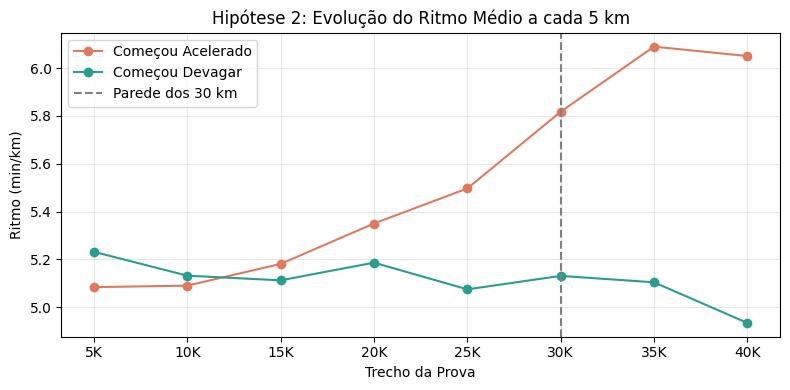

In [6]:
def analise_hipotese_2(df, colunas_ritmo):
    ritmos = df.groupby('Estrategia')[colunas_ritmo].mean()
    print(ritmos.T)

    trechos = ['5K', '10K', '15K', '20K', '25K', '30K', '35K', '40K']
    plt.figure(figsize=(8, 4))
    plt.plot(trechos, ritmos.loc['Começou Acelerado'], marker='o', label='Começou Acelerado', color='#e07a5f')
    plt.plot(trechos, ritmos.loc['Começou Devagar'], marker='o', label='Começou Devagar', color='#2a9d8f')
    plt.axvline('30K', color='gray', linestyle='--', label='Parede dos 30 km')
    plt.title('Hipótese 2: Evolução do Ritmo Médio a cada 5 km')
    plt.xlabel('Trecho da Prova')
    plt.ylabel('Ritmo (min/km)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


analise_hipotese_2(df, colunas_ritmo)

#4. Análise da Hipótese 3 (Fator preparação)

**Hipótese 3:** Corredores mais rápidos tendem a realizar uma prova em ritmo mais uniforme.

Nesta etapa, a função `analise_hipotese_3(df)` testa a terceira hipótese do estudo relacionando a oscilação de velocidade entre os oito trechos de 5 km (Variacao_Ritmo, calculada pelo desvio padrão do *pace*) com o tempo final de prova.

### Construção de gráficos para análise
* *Agrupamento por faixa de regularidade (`groupby` e `observed=False`)*: Agrupa os corredores nas três categorias criadas na preparação (Baixa Variação, Média Variação e Alta Variação) e calcula a contagem , a média e a mediana do tempo oficial;
* *Gráfico de barras (`plt.bar` e `plt.bar_label`)*: Exibe o tempo final médio de cada perfil de regularidade com os valores exatos impressos no topo de cada barra;

Ao analisar a tabela e o gráfico de barras, fica claro que quanto maior a oscilação de ritmo durante a prova, pior é o tempo final. Como a base foi dividida em três faixas iguais de **26.346 corredores**, a comparação é equilibrada entre os grupos. Os atletas de **Baixa Variação** (individuos que sustentaram um ritmo constante do início ao fim), concluíram a maratona com tempo médio de **206,0 minutos** (cerca de 3h26min) e mediana de **205,4 minutos**. Na faixa intermediária (**Média Variação**), o tempo médio sobe para **228,9 minutos** (cerca de 3h49min) e a mediana para **226,2 minutos**, um acréscimo de **22,9 minutos**.

Já no grupo de **Alta Variação** (individuos que optaram por uma largada agressiva) o tempo médio dispara para **264,2 minutos** (cerca de 4h24min) e a mediana para **259,1 minutos**. Numa comparação direta, corredores com ritmo constante completam a prova, em média, **58,2 minutos** (**22,0%**) mais rápido do que aqueles com alta oscilação (diferença que também se confirma na mediana, com **53,8 minutos** de vantagem). Esses resultados confirmam a Hipótese 3, reforçando que a regularidade de ritmo (*pacing* uniforme) é um fator determinante para o bom desempenho em maratonas.

                count        mean      median
Variacao_Ritmo                               
Baixa Variação  26346  205.976038  205.383333
Média Variação  26346  228.892028  226.216667
Alta Variação   26346  264.215962  259.133333


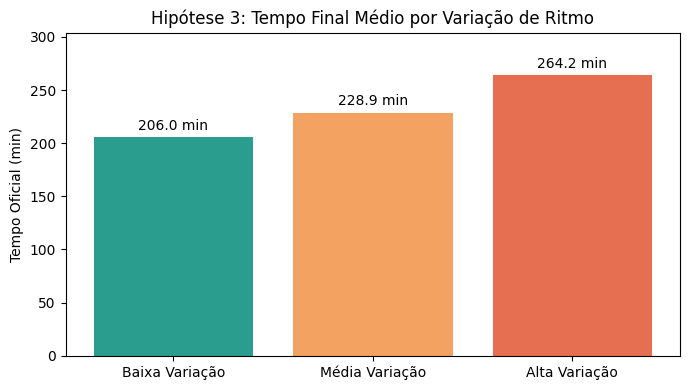

In [7]:
def analise_hipotese_3(df):
    resumo = df.groupby('Variacao_Ritmo', observed=False)['Official Time'].agg(['count', 'mean', 'median'])
    print(resumo)

    plt.figure(figsize=(7, 4))
    barras = plt.bar(resumo.index, resumo['mean'], color=['#2a9d8f', '#f4a261', '#e76f51'])
    plt.bar_label(barras, fmt='%.1f min', padding=3)
    plt.title('Hipótese 3: Tempo Final Médio por Variação de Ritmo')
    plt.ylabel('Tempo Oficial (min)')
    plt.ylim(0, resumo['mean'].max() * 1.15)
    plt.tight_layout()
    plt.show()


analise_hipotese_3(df)

#5. Limitações da Análise
* **Separação de atletas de elite e amadores:** Os dados demonstram que os corredores mais rápidos mantêm ritmo uniforme, mas isso também reflete maior experiência competitiva e nível de treinamento prévio. Largar devagar melhora a gestão de energia, mas não garante isoladamente um ganho de 18 minutos sem preparo físico compatível;
* **Abandono de prova:** O dataset registra apenas os atletas que cruzaram a linha de chegada, deixando de fora corredores que abandonaram a prova por exaustão após largarem em ritmo excessivamente forte e outros casos;
* **Fatores externos e características do percurso:** A análise unifica três anos distintos (2015, 2016 e 2017) sem separar variações climáticas específicas de cada edição (como temperatura, vento ou chuva), além de não isolar o efeito da altimetria particular da Maratona de Boston que é marcada por descidas acentuadas nos primeiros quilômetros (que incentivam largadas rápidas) e subidas exigentes após o km 26.

Esses pontos impactam o estudo porque não permitem afirmar que a diferença no tempo final acontece apenas por causa da estratégia escolhida. Como não foi possível separar atletas profissionais de amadores, parte do melhor resultado também vem do preparo físico e da experiência de cada corredor. Além disso, como os dados não mostram quem desistiu no meio da prova, o prejuízo de largar rápido demais pode ser ainda maior do que o calculado. E as caracteriscas do percurso junto com variações climáticas poderiam ajudar a compreender ainda mais essa quebra de ritmo a partir do km 30.

#6. Conclusão

A análise dos **79.038 registros válidos** da Maratona de Boston (2015–2017) confirma as três hipóteses levantadas e responde de forma clara à pergunta central do projeto: começar a prova em um ritmo mais controlado (devagar) e manter a regularidade traz resultados muito melhores do que largar acelerado. Embora a intuição leve **95,6%** dos corredores a forçarem o passo na primeira metade para tentar "ganhar tempo", os dados mostram que essa escolha provoca desgaste precoce e compromete o resultado final.

Na prática, a pequena minoria de **4,4%** que poupou energia no início (*negative split*) completou os 42 km com tempo médio de **215,2 minutos** (cerca de 3h35min), enquanto quem largou forte fechou em **233,9 minutos** (cerca de 3h54min), uma vantagem média de **18,7 minutos** (**8,0%** mais rápido), confirmando a **Hipótese 1**. O motivo dessa diferença fica evidente quando acompanhamos o ritmo a cada 5 km (**Hipótese 2**): quem começa acelerado sai forte nos primeiros 5 km (**5,08 min/km**), mas vai perdendo velocidade aos poucos até bater na "parede dos 30 km", caindo para **6,09 min/km** no km 35 (quase 20% mais lento que na largada). Já quem começa devagar (**5,23 min/km**) atravessa os 30 km sem sofrer quebra física e ainda guarda energia para acelerar na reta final, fechando o km 40 em **4,93 min/km**.

Além disso, a **Hipótese 3** comprovou que o bom desempenho está diretamente ligado à constância do ritmo. Corredores que mantiveram uma velocidade uniforme do começo ao fim concluíram a maratona em **206,0 minutos** (**3h26min**) na média, contra **264,2 minutos** (**4h24min**) daqueles que tiveram uma alta oscilação, uma diferença de quase uma hora (**58,2 minutos**). Portanto, o estudo conclui que, em provas de longa distância, ter paciência nos primeiros quilômetros e sustentar um ritmo equilibrado é a estratégia mais eficiente para alcançar o melhor tempo possível.
